# Oakland FloodWatch — starter notebook

**Goal:** find the parts of Oakland where **flood hazard** and **social vulnerability** overlap, so the city and
neighbors know where to focus drain cleaning, sandbags and flood investment.

This notebook pulls everything from free public sources (no API keys needed), builds a hexagon grid over
Oakland, and walks through:

1. Oakland boundary → H3 hex grid
2. OAK 311 flood reports (2013–today)
3. Terrain from USGS elevation (finding low spots)
4. FEMA flood zones
5. CDC Social Vulnerability Index (SVI)
6. A simple, spatially cross-validated flood-report model (+ "under-reported" hexes)
7. A combined **Flood Vulnerability Index** and interactive map
8. A check against the November 2026 storm

Every download is cached in `data/`, so re-running is fast and works offline once cached.
Cells marked **🔧 TEAM** are good places to make the project your own.

In [1]:
# If you're missing packages, uncomment:
# %pip install pandas geopandas shapely h3 requests scikit-learn folium matplotlib mapclassify

import json, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import geopandas as gpd
import h3
import requests
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, shape

DATA = Path("data"); DATA.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

H3_RES = 9           # ~0.1 km² hexes (~175 m edge). Try 8 (coarser) or 10 (finer).
CRS_M = "EPSG:26910"  # UTM zone 10N, metres — use for distances/areas
pd.set_option("display.max_columns", 50)

def get_json(url, params=None, cache=None, timeout=120):
    # GET a URL as JSON, caching the result to data/<cache> if given.
    if cache and (DATA / cache).exists():
        return json.loads((DATA / cache).read_text())
    r = requests.get(url, params=params, timeout=timeout)
    r.raise_for_status()
    js = r.json()
    if cache:
        (DATA / cache).write_text(json.dumps(js))
    return js

## 1. Oakland boundary and hex grid
The city boundary comes from the Census TIGERweb service (Oakland's place GEOID is `0653000`).

1,843 hexes at resolution 9


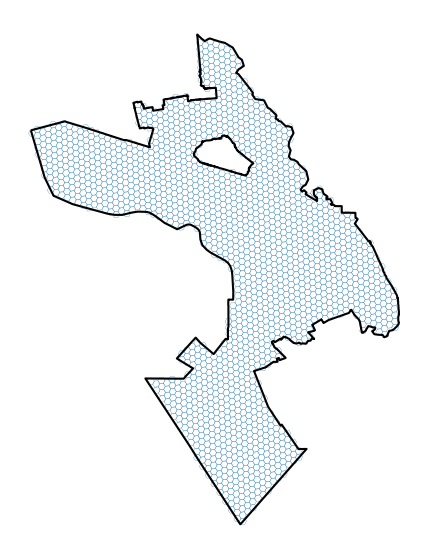

In [2]:
TIGER_PLACE = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/Places_CouSub_ConCity_SubMCD/MapServer/4/query"
js = get_json(TIGER_PLACE, {"where": "GEOID='0653000'", "outFields": "NAME,GEOID",
                            "outSR": 4326, "f": "geojson"}, cache="oakland_boundary.geojson")
oakland = gpd.GeoDataFrame.from_features(js["features"], crs=4326)
boundary = oakland.geometry.union_all()

cells = sorted(h3.geo_to_cells(boundary.__geo_interface__, H3_RES))
hexes = gpd.GeoDataFrame(
    {"h3": cells},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cells],
    crs=4326,
)
latlng = np.array([h3.cell_to_latlng(c) for c in cells])
hexes["lat"], hexes["lng"] = latlng[:, 0], latlng[:, 1]
print(f"{len(hexes):,} hexes at resolution {H3_RES}")
ax = hexes.boundary.plot(linewidth=0.2, figsize=(7, 7)); oakland.boundary.plot(ax=ax, color="k"); ax.set_axis_off()

## 2. OAK 311 flood reports
Dataset: [Service requests received by the Oakland Call Center](https://data.oaklandca.gov/) (Socrata id `quth-gb8e`).
`srx`/`sry` hold longitude/latitude.

Flood-related categories (counts as of Nov 2026): *Storm Drains – Clogged (Flooding)* ≈ 5.8k,
*Clogged (Not Flooding)* ≈ 5.6k, *Streets/Sidewalks – Pooling Water* ≈ 500, *Watershed – Overflow from a Creek* ≈ 20.

In [3]:
SOCRATA = "https://data.oaklandca.gov/resource/quth-gb8e.json"

# 🔧 TEAM: which 311 categories count as "flooding"?
FLOOD_CATS = [
    "Storm Drains - Clogged (Flooding)",
    "Streets/Sidewalks - Pooling Water",
    "Watershed - Overflow from a Creek",
]
DRAIN_CATS = [  # drain problems that weren't (yet) flooding — useful context
    "Storm Drains - Clogged (Not Flooding)",
    "Storm Inlet Grate - Damaged/Missing",
]

def fetch_311(categories, cache):
    path = DATA / cache
    if path.exists():
        return pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    cats = ",".join("'" + c.replace("'", "''") + "'" for c in categories)
    rows, offset = [], 0
    while True:
        batch = requests.get(SOCRATA, params={
            "$select": "requestid,datetimeinit,datetimeclosed,description,status,srx,sry,councildistrict,probaddress",
            "$where": f"description in ({cats})",
            "$order": "requestid", "$limit": 50000, "$offset": offset,
        }, timeout=120).json()
        rows += batch
        if len(batch) < 50000:
            break
        offset += 50000
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    return df

def clean_311(df):
    df = df.copy()
    df["lng"] = pd.to_numeric(df["srx"], errors="coerce")
    df["lat"] = pd.to_numeric(df["sry"], errors="coerce")
    df["datetimeinit"] = pd.to_datetime(df["datetimeinit"], errors="coerce")
    df["datetimeclosed"] = pd.to_datetime(df["datetimeclosed"], errors="coerce")
    minx, miny, maxx, maxy = boundary.bounds
    df = df[df.lng.between(minx, maxx) & df.lat.between(miny, maxy)]
    df["h3"] = [h3.latlng_to_cell(a, b, H3_RES) for a, b in zip(df.lat, df.lng)]
    return df[df.h3.isin(set(hexes.h3))]

flood = clean_311(fetch_311(FLOOD_CATS, "311_flood.csv"))
drain = clean_311(fetch_311(DRAIN_CATS, "311_drain.csv"))
print(f"{len(flood):,} flood reports, {len(drain):,} drain reports inside Oakland")
print("Date range:", flood.datetimeinit.min().date(), "→", flood.datetimeinit.max().date())
flood.description.value_counts()

6,166 flood reports, 6,220 drain reports inside Oakland
Date range: 2013-08-19 → 2026-11-15


description
Storm Drains - Clogged (Flooding)    5642
Streets/Sidewalks - Pooling Water     506
Watershed - Overflow from a Creek      18
Name: count, dtype: int64

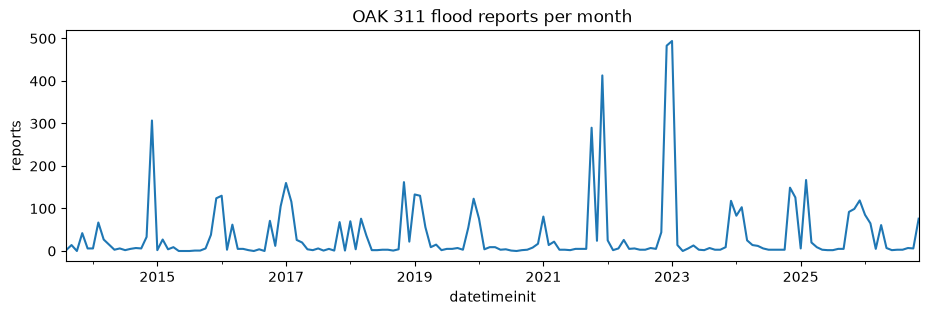

,reports
datetimeinit,
2023-01-01,494
2022-12-01,483
2021-12-01,413
2014-12-01,307
2021-10-01,290
2025-02-01,167
2018-11-01,162
2017-01-01,160


In [4]:
# When does Oakland flood? Reports per month — storm seasons and atmospheric rivers show up as spikes.
monthly = flood.set_index("datetimeinit").resample("MS").size()
ax = monthly.plot(figsize=(11, 3), title="OAK 311 flood reports per month")
ax.set_ylabel("reports"); plt.show()
monthly.sort_values(ascending=False).head(8).rename("reports").to_frame()

## 3. Terrain: elevation and local low spots
Elevation for each hex centre comes from the USGS 3DEP elevation service (lidar-based), sampled in
batches of 200 points, then cached.

`rel_elev_ft` compares a hex with its neighbours: **negative = a bowl where water collects.**

In [5]:
# USGS 3DEP ImageServer: sample many points per request (values in metres)
DEM = "https://elevation.nationalmap.gov/arcgis/rest/services/3DEPElevation/ImageServer/getSamples"
elev_cache = DATA / f"elevation_r{H3_RES}.csv"

def sample_batch(pts):
    geom = json.dumps({"points": pts, "spatialReference": {"wkid": 4326}})
    for attempt in range(4):
        try:
            r = requests.post(DEM, data={"geometry": geom, "geometryType": "esriGeometryMultipoint",
                                         "returnFirstValueOnly": "true", "f": "json"}, timeout=120)
            out = np.full(len(pts), np.nan)
            for s in r.json()["samples"]:
                try:
                    out[s["locationId"]] = float(s["value"]) * 3.28084   # metres → feet
                except (TypeError, ValueError):
                    pass   # NoData (open water)
            return out
        except Exception:
            time.sleep(2 + 2 * attempt)
    return np.full(len(pts), np.nan)

if elev_cache.exists():
    elev = pd.read_csv(elev_cache)
else:
    pts = hexes[["lng", "lat"]].values.tolist()
    batches = [pts[i:i + 200] for i in range(0, len(pts), 200)]
    with ThreadPoolExecutor(max_workers=4) as pool:
        vals = np.concatenate(list(pool.map(sample_batch, batches)))
    elev = pd.DataFrame({"h3": hexes.h3, "elev_ft": vals})
    elev.to_csv(elev_cache, index=False)

hexes = hexes.drop(columns=["elev_ft"], errors="ignore").merge(elev, on="h3", how="left")
e = hexes.set_index("h3").elev_ft.to_dict()

def neighbour_stats(c, k=2):
    vals = [e.get(n) for n in h3.grid_disk(c, k) if n != c]
    vals = [v for v in vals if v is not None and not np.isnan(v)]
    return (np.mean(vals), np.std(vals)) if vals else (np.nan, np.nan)

ns = np.array([neighbour_stats(c) for c in hexes.h3])
hexes["rel_elev_ft"] = hexes.elev_ft - ns[:, 0]   # negative = lower than surroundings
hexes["slope_proxy"] = ns[:, 1]                   # spread of neighbour elevations ≈ steepness
print(hexes[["elev_ft", "rel_elev_ft", "slope_proxy"]].describe().round(1))

       elev_ft  rel_elev_ft  slope_proxy
count   1843.0       1843.0       1843.0
mean     211.3          1.3         51.7
std      343.6         61.3         69.6
min      -30.7       -305.5          0.2
25%        0.5         -6.5          3.2
50%       26.7         -0.4         11.9
75%      265.9          3.2         85.2
max     1708.9        445.8        280.4


## 4. FEMA flood zones
From FEMA's National Flood Hazard Layer (NFHL), layer 28 = flood hazard zones.
- **SFHA** (zones A, AE, AH, AO, VE) = the official "100-year" floodplain.
- **X (0.2 PCT)** = the 500-year floodplain.

In [6]:
NFHL = "https://hazards.fema.gov/arcgis/rest/services/public/NFHL/MapServer/28/query"
minx, miny, maxx, maxy = boundary.bounds
fema_cache = DATA / "fema_nfhl_zones.geojson"
if not fema_cache.exists():
    feats, offset = [], 0
    while True:
        js = requests.get(NFHL, params={
            "geometry": f"{minx},{miny},{maxx},{maxy}", "geometryType": "esriGeometryEnvelope",
            "inSR": 4326, "outSR": 4326, "spatialRel": "esriSpatialRelIntersects",
            "outFields": "FLD_ZONE,ZONE_SUBTY,SFHA_TF", "maxAllowableOffset": 0.00002,
            "resultOffset": offset, "resultRecordCount": 1000, "f": "geojson",
        }, timeout=180).json()
        feats += js["features"]
        if len(js["features"]) < 1000:
            break
        offset += 1000
    fema_cache.write_text(json.dumps({"type": "FeatureCollection", "features": feats}))

fema = gpd.read_file(fema_cache).set_crs(4326, allow_override=True)
fema["geometry"] = fema.geometry.make_valid()
sfha = fema[fema.SFHA_TF == "T"]
x500 = fema[fema.ZONE_SUBTY.fillna("").str.contains("0.2 PCT")]
print(fema.FLD_ZONE.value_counts())

centroids = gpd.GeoDataFrame(hexes[["h3"]], geometry=gpd.points_from_xy(hexes.lng, hexes.lat), crs=4326)
hexes["in_sfha"] = centroids.within(sfha.union_all()).astype(int).values
hexes["in_500yr"] = centroids.within(x500.union_all()).astype(int).values
sfha_m = sfha.to_crs(CRS_M).union_all()
hexes["dist_sfha_m"] = centroids.to_crs(CRS_M).distance(sfha_m).values
print(f"{hexes.in_sfha.sum()} hexes in the 100-yr floodplain, {hexes.in_500yr.sum()} in the 500-yr")

FLD_ZONE
X             879
AE            271
AO            121
VE             33
A              28
AH             10
OPEN WATER      5
D               3
Name: count, dtype: int64


129 hexes in the 100-yr floodplain, 110 in the 500-yr


## 5. Social vulnerability (CDC/ATSDR SVI 2022, census tracts)
The SVI ranks every US tract from 0 (least vulnerable) to 1 (most) using 16 American Community Survey
variables. We keep the overall rank plus a few flood-relevant ones (people with no car can't evacuate easily;
limited-English households miss warnings; renters can't fix drainage themselves).

*Using SVI avoids the Census API, which now requires a free key. If you get one, you can pull any ACS variable you like.*

In [7]:
svi_path = DATA / "svi_2022_california.csv"
if not svi_path.exists():
    r = requests.get("https://svi.cdc.gov/Documents/Data/2022/csv/states/California.csv", timeout=300)
    r.raise_for_status(); svi_path.write_bytes(r.content)

SVI_COLS = {  # 🔧 TEAM: add/remove indicators
    "RPL_THEMES": "svi_overall", "EP_POV150": "pct_below_150_poverty", "EP_AGE65": "pct_65_plus",
    "EP_DISABL": "pct_disability", "EP_LIMENG": "pct_limited_english", "EP_NOVEH": "pct_no_vehicle",
    "EP_MUNIT": "pct_multiunit_housing", "E_TOTPOP": "population", "AREA_SQMI": "area_sqmi",
}
svi = pd.read_csv(svi_path, dtype={"FIPS": str}, usecols=["FIPS", *SVI_COLS])
svi["FIPS"] = svi.FIPS.str.zfill(11)
svi = svi[svi.FIPS.str.startswith("06001")].rename(columns=SVI_COLS).replace(-999, np.nan)
svi["pop_density"] = svi.population / svi.area_sqmi

TIGER_TRACTS = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/Tracts_Blocks/MapServer/0/query"
js = get_json(TIGER_TRACTS, {"where": "STATE='06' AND COUNTY='001'", "outFields": "GEOID",
                             "outSR": 4326, "f": "geojson"}, cache="alameda_tracts.geojson")
tracts = gpd.GeoDataFrame.from_features(js["features"], crs=4326).merge(svi, left_on="GEOID", right_on="FIPS")

joined = gpd.sjoin(centroids, tracts.drop(columns=["FIPS"]), how="left", predicate="within")
joined = joined[~joined.index.duplicated()]
for col in ["GEOID", *SVI_COLS.values(), "pop_density"]:
    hexes[col] = joined[col].values

# Drop hexes that are open water / have no residents data
hexes = hexes[hexes.elev_ft.notna() & hexes.GEOID.notna()].reset_index(drop=True)
print(f"{len(hexes):,} land hexes with tract data")

1,448 land hexes with tract data


## 6. Model: where *should* we expect flood reports?
Target = did this hex ever get a 311 flood report? Features = terrain, FEMA zones and population density
(more people → more reports, so we control for it).

We use **spatial cross-validation**: hexes are grouped into larger parent cells so the model is always
tested on neighbourhoods it hasn't seen (otherwise neighbouring hexes leak answers and accuracy looks too good).

The interesting output is the **gap**: hexes the model rates as flood-prone but which have *no* reports.
These may be **under-reported**, often in areas where residents are less likely to use 311.

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

counts = flood.groupby("h3").size().rename("flood_reports")
dcounts = drain.groupby("h3").size().rename("drain_reports")
hexes = hexes.drop(columns=["flood_reports", "drain_reports"], errors="ignore") \
             .merge(counts, on="h3", how="left").merge(dcounts, on="h3", how="left")
hexes[["flood_reports", "drain_reports"]] = hexes[["flood_reports", "drain_reports"]].fillna(0)
hexes["y"] = (hexes.flood_reports > 0).astype(int)

FEATURES = ["elev_ft", "rel_elev_ft", "slope_proxy", "in_sfha", "in_500yr", "dist_sfha_m", "pop_density"]
X, y = hexes[FEATURES], hexes.y
groups = [h3.cell_to_parent(c, 6) for c in hexes.h3]   # ~36 km² blocks for spatial CV

oof = np.zeros(len(hexes))
for train, test in GroupKFold(n_splits=5).split(X, y, groups):
    m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0)
    m.fit(X.iloc[train], y.iloc[train])
    oof[test] = m.predict_proba(X.iloc[test])[:, 1]

hexes["p_flood"] = oof
print(f"Share of hexes with ≥1 flood report: {y.mean():.0%}")
print(f"Spatial-CV ROC AUC: {roc_auc_score(y, oof):.3f}   PR AUC: {average_precision_score(y, oof):.3f} "
      f"(baseline {y.mean():.3f})")

Share of hexes with ≥1 flood report: 58%
Spatial-CV ROC AUC: 0.837   PR AUC: 0.847 (baseline 0.578)


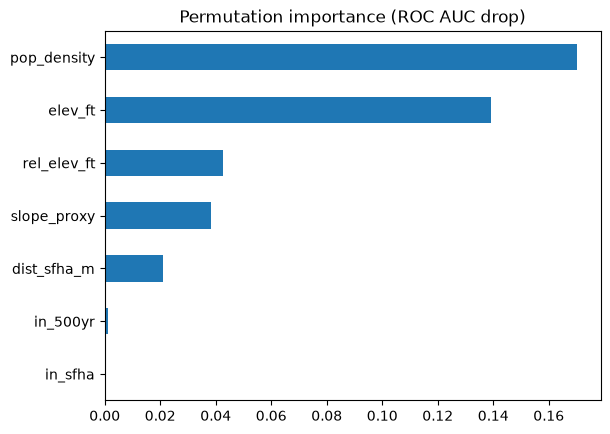

48 possibly under-reported hexes


,svi_overall,pct_limited_english,pct_below_150_poverty
maybe_underreported,,,
0,0.42,5.50,16.53
1,0.47,7.38,18.41


In [9]:
# Which features matter? (permutation importance on a model fit to everything)
from sklearn.inspection import permutation_importance
full = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0).fit(X, y)
pi = permutation_importance(full, X, y, scoring="roc_auc", n_repeats=10, random_state=0)
pd.Series(pi.importances_mean, index=FEATURES).sort_values().plot.barh(title="Permutation importance (ROC AUC drop)")
plt.show()

# Possibly under-reported: model says top-25% risk, but zero flood reports ever.
thresh = hexes.p_flood.quantile(0.75)
hexes["maybe_underreported"] = ((hexes.p_flood >= thresh) & (hexes.flood_reports == 0)).astype(int)
print(f"{hexes.maybe_underreported.sum()} possibly under-reported hexes")
hexes.groupby("maybe_underreported")[["svi_overall", "pct_limited_english", "pct_below_150_poverty"]].mean().round(2)

## 7. Flood Vulnerability Index
**Hazard** blends three signals (each converted to a 0–1 percentile):
the model's predicted risk, actual report history, and FEMA zone.
**Vulnerability** is the CDC SVI rank. The final index is their weighted geometric mean, so a hex must
score high on *both* to rank at the top.

🔧 **TEAM:** these weights are judgment calls. Show judges how the ranking shifts when you change them.

In [10]:
W_HAZARD = {"model": 0.4, "reports": 0.3, "fema": 0.3}
W_INDEX = {"hazard": 0.5, "vulnerability": 0.5}

pct = lambda s: s.rank(pct=True)
hexes["fema_score"] = np.select([hexes.in_sfha == 1, hexes.in_500yr == 1], [1.0, 0.5], 0.0)
hexes["hazard"] = (W_HAZARD["model"] * pct(hexes.p_flood)
                   + W_HAZARD["reports"] * pct(hexes.flood_reports + 0.5 * hexes.drain_reports)
                   + W_HAZARD["fema"] * hexes.fema_score)
hexes["hazard"] = pct(hexes.hazard)
hexes["vulnerability"] = hexes.svi_overall.fillna(hexes.svi_overall.median())
hexes["fvi"] = (hexes.hazard ** W_INDEX["hazard"]) * (hexes.vulnerability ** W_INDEX["vulnerability"])

def why(r):
    reasons = []
    if r.in_sfha: reasons.append("FEMA 100-yr floodplain")
    elif r.in_500yr: reasons.append("FEMA 500-yr floodplain")
    if r.rel_elev_ft < -3: reasons.append(f"low spot ({r.rel_elev_ft:.0f} ft below neighbours)")
    if r.flood_reports: reasons.append(f"{int(r.flood_reports)} flood reports")
    if r.maybe_underreported: reasons.append("likely under-reported")
    if r.pct_no_vehicle >= 20: reasons.append(f"{r.pct_no_vehicle:.0f}% no car")
    if r.pct_limited_english >= 10: reasons.append(f"{r.pct_limited_english:.0f}% limited English")
    if r.svi_overall >= 0.8: reasons.append(f"SVI {r.svi_overall:.2f}")
    return "; ".join(reasons)

hexes["why"] = hexes.apply(why, axis=1)
top = hexes.sort_values("fvi", ascending=False).head(15)
top[["h3", "fvi", "hazard", "vulnerability", "flood_reports", "elev_ft", "why"]].round(2)

,h3,fvi,hazard,vulnerability,flood_reports,elev_ft,why
1004,89283098b83ffff,0.99,1.00,0.99,18.0,53.92,FEMA 500-yr floodplain; 18 flood reports; 28% ...
1078,89283098e53ffff,0.98,0.98,0.99,3.0,21.83,FEMA 500-yr floodplain; 3 flood reports; SVI 0.99
1079,89283098e57ffff,0.98,0.97,0.99,4.0,12.27,FEMA 500-yr floodplain; low spot (-9 ft below ...
824,89283098327ffff,0.98,0.97,0.99,2.0,26.11,FEMA 500-yr floodplain; 2 flood reports; SVI 0.99
955,89283098a83ffff,0.97,0.97,0.98,18.0,48.74,low spot (-9 ft below neighbours); 18 flood re...
1010,89283098b9bffff,0.97,1.00,0.94,16.0,53.81,FEMA 500-yr floodplain; 16 flood reports; 20% ...
961,89283098a9bffff,0.97,0.95,0.98,11.0,44.56,low spot (-8 ft below neighbours); 11 flood re...
896,89283098863ffff,0.96,0.99,0.94,3.0,36.68,FEMA 500-yr floodplain; low spot (-5 ft below ...
899,8928309886fffff,0.96,0.98,0.94,2.0,47.71,FEMA 500-yr floodplain; low spot (-9 ft below ...
1060,89283098e03ffff,0.96,1.00,0.92,33.0,10.49,FEMA 500-yr floodplain; low spot (-4 ft below ...


In [11]:
# Roll up to census tracts — easier to talk about than hexes
by_tract = (hexes.groupby("GEOID")
            .agg(mean_fvi=("fvi", "mean"), max_fvi=("fvi", "max"), flood_reports=("flood_reports", "sum"),
                 hexes_in_sfha=("in_sfha", "sum"), svi=("svi_overall", "first"),
                 population=("population", "first"))
            .sort_values("mean_fvi", ascending=False))
by_tract.head(10).round(2)

,mean_fvi,max_fvi,flood_reports,hexes_in_sfha,svi,population
GEOID,,,,,,
06001406202,0.95,0.99,26.0,0,0.99,4733.0
06001407200,0.94,0.97,38.0,0,0.94,6544.0
06001408900,0.93,0.98,32.0,0,0.99,3956.0
06001408800,0.93,0.96,166.0,0,0.92,7968.0
06001407500,0.92,0.97,36.0,0,0.98,3988.0
06001407400,0.92,0.96,15.0,0,0.92,4242.0
06001406201,0.92,0.95,38.0,0,0.94,5072.0
06001408400,0.91,0.94,48.0,0,0.90,4077.0
06001408500,0.91,0.93,60.0,0,0.87,5634.0


## 8. Map

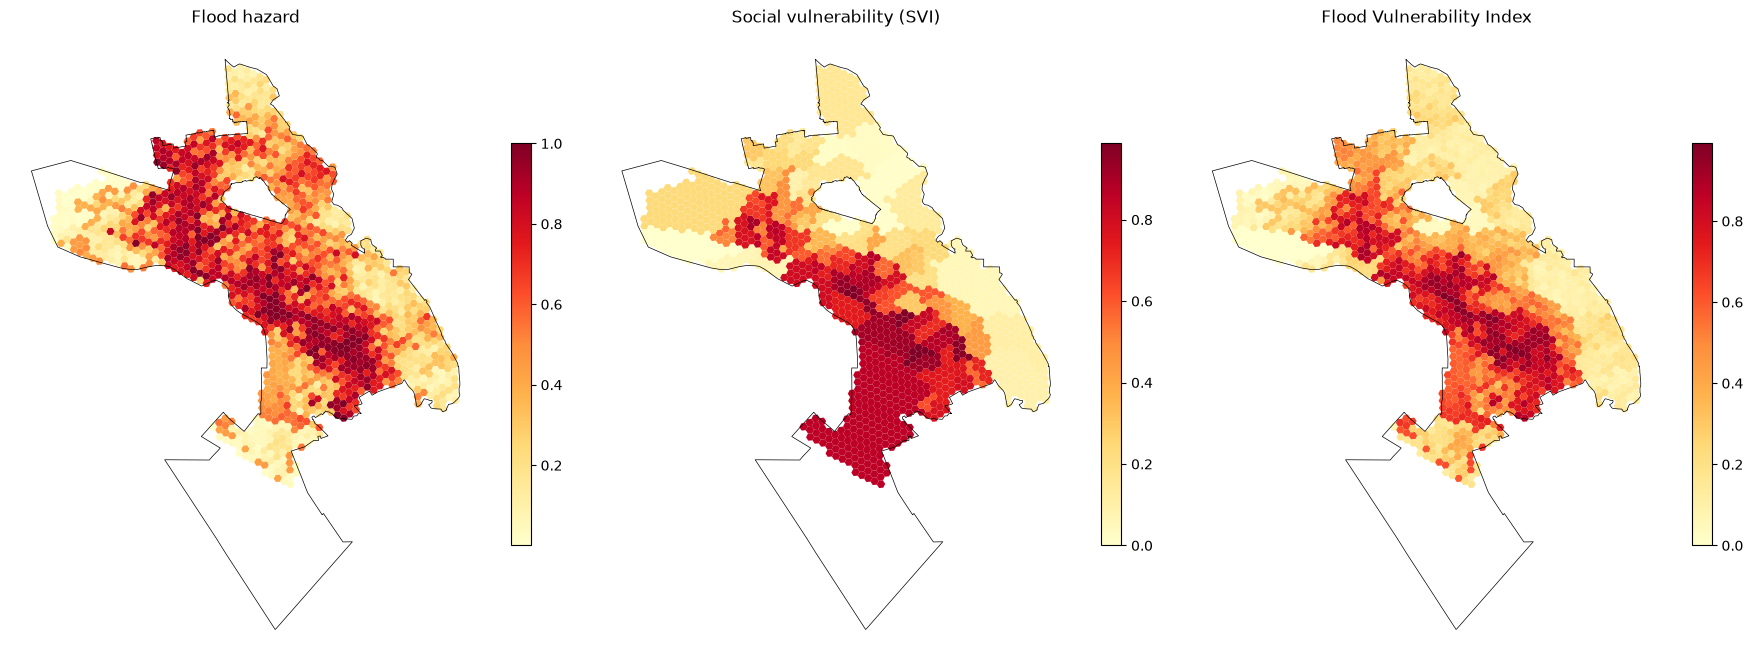

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, col, title in zip(axes, ["hazard", "vulnerability", "fvi"],
                          ["Flood hazard", "Social vulnerability (SVI)", "Flood Vulnerability Index"]):
    hexes.plot(column=col, cmap="YlOrRd", ax=ax, legend=True, legend_kwds={"shrink": 0.6})
    oakland.boundary.plot(ax=ax, color="k", linewidth=0.5)
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout(); plt.savefig(OUT / "fvi_maps.png", dpi=150); plt.show()

In [13]:
import folium

m = folium.Map(location=[37.79, -122.22], zoom_start=12, tiles="OpenStreetMap")
layer = hexes[["h3", "geometry", "fvi", "hazard", "vulnerability", "flood_reports", "elev_ft", "why"]].copy()
layer[["fvi", "hazard", "vulnerability", "elev_ft"]] = layer[["fvi", "hazard", "vulnerability", "elev_ft"]].round(2)
folium.Choropleth(geo_data=layer.__geo_interface__, data=layer, columns=["h3", "fvi"],
                  key_on="feature.properties.h3", fill_color="YlOrRd", fill_opacity=0.65,
                  line_opacity=0.1, legend_name="Flood Vulnerability Index").add_to(m)
folium.GeoJson(layer.__geo_interface__, style_function=lambda f: {"fillOpacity": 0, "weight": 0},
               tooltip=folium.GeoJsonTooltip(["fvi", "hazard", "vulnerability", "flood_reports", "elev_ft", "why"])
               ).add_to(m)
folium.GeoJson(sfha.__geo_interface__, name="FEMA 100-yr floodplain",
               style_function=lambda f: {"color": "#1f6feb", "weight": 1, "fillOpacity": 0.1}).add_to(m)
folium.LayerControl().add_to(m)
m.save(OUT / "flood_vulnerability_map.html")
m

## 9. Backtest: could we have predicted the 2022–23 atmospheric river floods?
Dec 2022 and Jan 2023 brought Oakland's most flood reports on record. We **train only on reports before
Dec 2022**, then check how many of the hexes that flooded during those storms we had ranked as high risk.
This is the most convincing result to show judges: "Our model, using only earlier data, would have flagged X% of
the flooded blocks by checking just Y% of the city."

In [14]:
CUTOFF, STORM_END = pd.Timestamp("2022-12-01"), pd.Timestamp("2023-02-01")
before = flood[flood.datetimeinit < CUTOFF].groupby("h3").size()
during = set(flood[flood.datetimeinit.between(CUTOFF, STORM_END)].h3)

bt = hexes[["h3", *FEATURES]].copy()
bt["y_before"] = bt.h3.map(before).fillna(0).gt(0).astype(int)
bt["storm_hit"] = bt.h3.isin(during).astype(int)
model_bt = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0)
model_bt.fit(bt[FEATURES], bt.y_before)
bt["score"] = model_bt.predict_proba(bt[FEATURES])[:, 1]

print(f"{len(during)} hexes had flood reports during the 2022–23 storms")
print(f"ROC AUC (model trained pre-storm): {roc_auc_score(bt.storm_hit, bt.score):.3f}")
for share in (0.1, 0.2, 0.3):
    k = int(share * len(bt))
    caught = bt.nlargest(k, "score").storm_hit.sum()
    print(f"  Checking the top {share:.0%} of hexes would have caught {caught/len(during):.0%} of flooded hexes")

432 hexes had flood reports during the 2022–23 storms
ROC AUC (model trained pre-storm): 0.785
  Checking the top 10% of hexes would have caught 22% of flooded hexes
  Checking the top 20% of hexes would have caught 39% of flooded hexes
  Checking the top 30% of hexes would have caught 53% of flooded hexes


## 10. Did the model see the November 2026 storm coming?
The Nov 18, 2026 storm dropped ~1.5–3" of rain and flooded West Oakland and downtown streets.
The 311 dataset updates with a lag of a few days. If it's empty, re-run later (delete `data/311_flood.csv` first).

A good validation: **train on reports before the storm, then check whether the storm's reports fell in hexes you ranked high.**

In [15]:
STORM_START = pd.Timestamp("2026-11-17")
storm = flood[flood.datetimeinit >= STORM_START]
print(f"{len(storm)} flood reports since {STORM_START.date()} (data through {flood.datetimeinit.max().date()})")
if len(storm):
    storm_hexes = set(storm.h3)
    hexes["storm_hit"] = hexes.h3.isin(storm_hexes).astype(int)
    print("ROC AUC of hazard score vs storm reports:", round(roc_auc_score(hexes.storm_hit, hexes.hazard), 3))
    for k in (50, 100, 200):
        hit = hexes.nlargest(k, "hazard").storm_hit.sum()
        print(f"  top {k} hazard hexes captured {hit}/{len(storm_hexes)} storm-flooded hexes")
else:
    print("No storm reports in the data yet — try again in a few days.")

0 flood reports since 2026-11-17 (data through 2026-11-15)
No storm reports in the data yet — try again in a few days.


In [16]:
# Save results for a dashboard / Streamlit app
hexes.drop(columns="geometry").to_csv(OUT / "hex_scores.csv", index=False)
hexes[["h3", "fvi", "hazard", "vulnerability", "why", "geometry"]].to_file(OUT / "hex_scores.geojson", driver="GeoJSON")
by_tract.to_csv(OUT / "tract_scores.csv")
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['flood_vulnerability_map.html', 'fvi_maps.png', 'hex_scores.csv', 'hex_scores.geojson', 'tract_scores.csv']


## Next steps / stretch ideas
- **Sea level rise:** add NOAA's Sea Level Rise Viewer depth grids (1, 2, 3 ft) or USGS CoSMoS layers as
  features and let a slider re-score the map. The Bay shoreline (West Oakland, Coliseum/Airport, San Leandro Bay)
  will light up.
- **Rain + tide:** join daily rainfall (NOAA GHCN station at Oakland Airport, `USW00023230`) and tide height (NOAA tide
  gauge Alameda `9414750`) to monthly reports. Floods are worst when storms meet king tides.
- **Creeks and storm drains:** add distance to creeks and storm drain density from the Oakland open data portal
  or Alameda County Flood Control.
- **Rising groundwater:** overlay shallow-groundwater projections for the shoreline and state toxic-site data
  (DTSC EnviroStor / GeoTracker) to flag contamination risk.
- **Redlining:** overlay 1937 HOLC maps (Mapping Inequality, Univ. of Richmond) to show how today's risk tracks historic disinvestment.
- **Adopt-a-Drain targeting:** rank individual storm drains in high-FVI hexes so volunteers clear the drains that matter most.
- **Demo app:** load `outputs/hex_scores.geojson` into Streamlit + pydeck with weight sliders.